# Import necessary libraries, load the 'students.csv' dataset, display a data sample, determine dataset dimensions, and view the summary statistics for both quantitative and qualitative columns.

In [10]:
# import the necessary lib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#Read and show 'students.csv'
df = pd.read_csv(r"C:\pp\ml--2026\tsv\students.csv")
df.head()
df.shape

(8239, 16)

In [14]:
#show the summary statistics for qantitative and qualitative columns
df.describe()

,stud.id,age,height,weight,nc.score,score1,score2,online.tutorial,graduated,salary
count,8239.000000,8239.000000,8239.000000,8239.000000,8239.000000,4892.000000,4892.000000,8239.000000,8239.000000,1753.000000
mean,548910.484525,22.541571,171.380750,72.998131,2.166481,68.164963,69.494685,0.386212,0.212769,42522.112364
std,253849.389811,6.065111,11.077529,8.635162,0.811548,14.051762,14.395251,0.486910,0.409290,10333.139906
min,110250.000000,18.000000,135.000000,51.400000,1.000000,30.000000,31.000000,0.000000,0.000000,11444.141650
25%,331222.500000,20.000000,163.000000,66.500000,1.460000,58.000000,59.000000,0.000000,0.000000,35206.541600
50%,545132.000000,21.000000,171.000000,71.800000,2.040000,70.000000,71.000000,0.000000,0.000000,41672.009750
75%,770807.500000,23.000000,180.000000,78.500000,2.780000,78.000000,80.000000,1.000000,0.000000,49372.540910
max,989901.000000,64.000000,206.000000,116.000000,4.000000,97.000000,98.000000,1.000000,1.000000,75596.793440


# 1: Q1 Draw a histogram of 'weight' and provide a short description of your observations with identifying the distribution

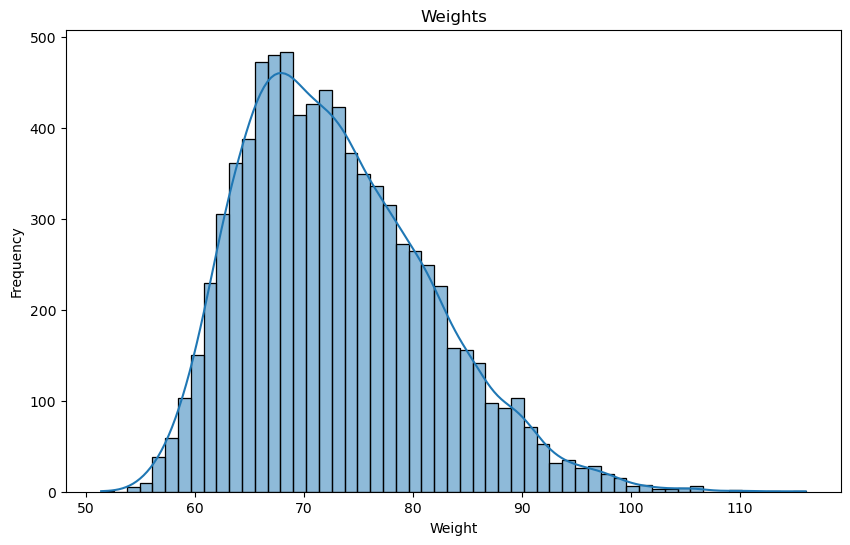

In [18]:
# Draw a histogram for 'weight'
plt.figure(figsize=(10, 6))
sns.histplot(df['weight'], kde=True)
plt.title('Weights')
plt.xlabel('Weight')
plt.ylabel('Frequency')
plt.show()

The histogram shows the frequency of weight values among students.
symmetrical around the mean, it follows a Normal distribution.

# Q2: Calculate the skewness of 'weight' and explain its significance

In [23]:
skew = df["weight"].skew()
print(skew)

0.6510039648535437


skewness > 0
positive symmetric more values more than average value 

# Q3: What is the probability that a student's weight is between 70 kg and 80 kg? Here, you should use the right distribution function and probability function from scipy.stats


In [28]:
#calculate the mean of weight
mean = df["weight"].mean()

#calculate the std of weight
std = df["weight"].std()

#calculate the zscore of the heights
from scipy import stats
df["height_zscore"] = stats.zscore(df["height"])
print(df[['height', 'height_zscore']].head())

#calculate the probability required
# P(70 < X < 80)
prob_between = stats.norm.cdf(80, loc=mean, scale=std) - \
               stats.norm.cdf(70, loc=mean, scale=std)


   height  height_zscore
0     160      -1.027435
1     172       0.055905
2     168      -0.305208
3     183       1.048966
4     175       0.326740


# Q4: What is the probability that a student's weight is less than 70 Kg ?

In [31]:
# P(X < 70)
prob_less_70 = stats.norm.cdf(70, loc=mean, scale=std)

print(mean) # mean weight
print(std) #std weight
print(prob_between) # 70kg < weight < 80kg
print(prob_less_70) # weight < 70kg

72.9981308411215
8.635161688392094
0.42705528013215666
0.3642204178502998


# Q5: What is the probability that a student's weight is greater than 70 Kg ?


In [32]:
prob_greater_70 = 1 - prob_less_70

print(prob_greater_70)

0.6357795821497002


# Q6: A company produces electronic components, and their quality control process involves testing each component for defects. The defect rate for these components is 6%. The company recently received a large order for 300 components. They want to determine the probability of having a certain number of defective components in this order.

In [37]:
n_comp = 300
p_def = 0.06

prob_exactly_18 = stats.binom.pmf(18, n_comp, p_def)

print(n_comp * p_def) #Expected number of defects (n*p)
print(prob_exactly_18) #Prob(Exactly 18 defects

print(df[['height', 'height_zscore']].head())

18.0
0.09653654916516442
   height  height_zscore
0     160      -1.027435
1     172       0.055905
2     168      -0.305208
3     183       1.048966
4     175       0.326740


# Question 6.1: What is the probability that exactly 10 components out of an order of 300 are defective?

In [39]:
n = 300
p = 0.02 
k = 10

prob_exactly_10 = stats.binom.pmf(k, n, p)
print(prob_exactly_10)

0.04087601494463424


# Question 6.2: What is the probability that minimum 10 components out of an order of 300 are defective?

In [40]:
prob_min_10 = 1 - stats.binom.cdf(k - 1, n, p)
print(prob_min_10)

0.08183807400926058


# Question 6.3: What is the probability that maximum 10 components out of an order of 300 are defective?


In [41]:
prob_max_10 = stats.binom.cdf(k, n, p)
print(prob_max_10)

0.9590379409353739


# Question 6.3: Calculate the number of components that are likely to be defective and the standard deviation of the defect probabilities for the 300 components.


In [43]:
mean = n * p
std_dev = np.sqrt(n * p * (1 - p))
print(std_dev)

2.4248711305964283
